# Figure 5 Supplement 2: When is a collapsing bound optimal?

The reward-rate-optimal stopping policy in mixed-SNR blocks, with and without zero-SNR trials, by
dynamic programming (`pigeon.ideal_observer.get_optimal_bounds_mixture`). Each trial's step mean is
0 (a zero-SNR trial, its correct side a coin flip) with probability equal to the zero-SNR share, and
otherwise 0.05 or 0.15 (the task's low and high SNR, equally likely), in a random direction. Step SD
0.15. The observer knows this mixture but not the trial's SNR, so its belief about the SNR changes
with the position and the step, and the optimal bound can change over the trial.

Costs follow the three penalty conditions (`BLOCK_DEFAULTS` 1–3): 1 coin per correct response; an
error costs nothing, 4 coins, or 30 extra steps. Each trial also costs the trial-start step plus the
mean non-decision time (cohort 2's fitted P(NDT = 1)). A trial still running at step 300 ends with a
forced response. Each optimal policy is compared with the best flat bound
(`get_best_flat_bound`), computed on the same grid with the same rules.

The results are computed by `scripts/run_optimal_collapse.py` (`data/processed/optimal_collapse.pkl`).
The zero-SNR share goes up to 1/3, i.e. the three step means equally likely. At a 1/2 share with the
4-coin penalty the best reward rate is negative (not playing would be better), so the comparison is
not meaningful there.

- **Top row (A–C):** the optimal bound over the trial for several zero-SNR shares.
- **Middle row (D–F):** the optimal policy's reward-rate gain over the best flat bound, in percent.
- **Bottom row (G–I):** the same gain in coins per block (600 steps), the scale a participant sees.


In [1]:
import sys

sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import CM, CONDITION_LABELS, FS_INSET, OPTIMAL_COLOR, add_panel_label, use_figure_style
from pigeon.simulation import BLOCK_DEFAULTS

res = pd.read_pickle(DATA_DIR / 'optimal_collapse.pkl')
_mx = pd.read_pickle(DATA_DIR / 'stopping_fits_main.pkl').query("task == 'MX'")
_p1 = float(_mx.groupby('subject_index').ndt_p1.first().mean())
start_cost = 1 + _p1 + 2 * (1 - _p1)
print(f'steps charged per trial besides the decision: {res.start_cost.iloc[0]:.3f} in the results, '
      f'{start_cost:.3f} from the current fits')
# a refit moves the mean NDT slightly; rerun the script if the cost per trial moves by more than 0.01 steps
assert abs(res.start_cost.iloc[0] - start_cost) < 0.01, 'rerun scripts/run_optimal_collapse.py'

summary = res.drop(columns='bound').copy()
summary['condition'] = summary.block.map(CONDITION_LABELS)
summary['gain (coins/step)'] = summary.rho_opt - summary.rho_flat
STEPS_PER_BLOCK = BLOCK_DEFAULTS[1]['steps_per_block']
assert all(BLOCK_DEFAULTS[b]['steps_per_block'] == STEPS_PER_BLOCK for b in (1, 2, 3))
res['gain_per_block'] = STEPS_PER_BLOCK * (res.rho_opt - res.rho_flat)
summary['coins per block (flat)'] = STEPS_PER_BLOCK * summary.rho_flat
summary['gain (coins/block)'] = res.gain_per_block
for t in (1, 10, 30, 100):
    summary[f'bound at {t}'] = [b[t] for b in res.bound]
pd.set_option('display.width', 200)
print(summary.drop(columns=['block', 'start_cost']).round(4).to_string(index=False))


steps charged per trial besides the decision: 2.396 in the results, 2.396 from the current fits
 zero_share  rho_opt  rho_flat  b_flat  gain_pct    condition  gain (coins/step)  coins per block (flat)  gain (coins/block)  bound at 1  bound at 10  bound at 30  bound at 100
     0.0000   0.2167    0.2167  0.0000    0.0000   No penalty             0.0000                130.0257              0.0000        0.00         0.00         0.00          0.00
     0.0500   0.2132    0.2132  0.0000    0.0000   No penalty             0.0000                127.9417              0.0000        0.00         0.00         0.00          0.00
     0.1000   0.2098    0.2098  0.0000    0.0000   No penalty             0.0000                125.8578              0.0000        0.00         0.00         0.00          0.00
     0.1500   0.2063    0.2063  0.0000    0.0000   No penalty             0.0000                123.7738              0.0000        0.00         0.00         0.00          0.00
     0.2000   0.202

## Figure

Top row: optimal bound (|position| at which to respond) at each step, one line per zero-SNR share (darker
= more zero-SNR trials); a bound of 0 means "respond at once" (with no penalty, the optimal policy and
the best flat bound both respond at the first step). Middle row: reward-rate gain of the optimal policy
over the best flat bound, in percent; bottom row: the same gain in coins per 600-step block. Red = optimal benchmark. Saves `Figure05_S02.pdf` (+ `.png`)
to `FIGURES_DIR`.


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


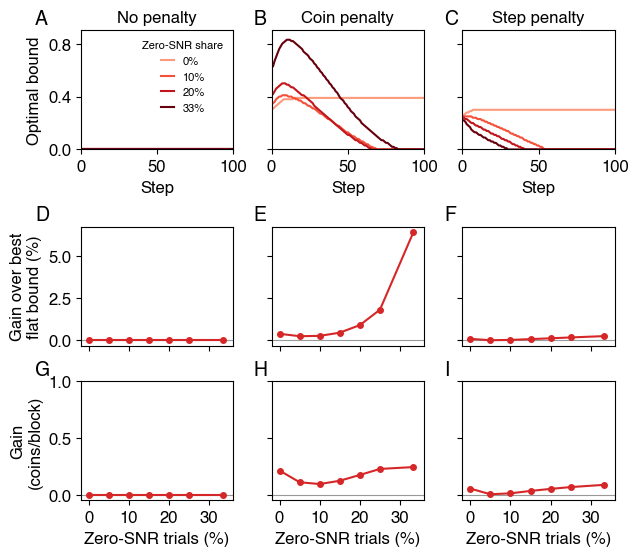

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05_S02.pdf (+ .png)


In [2]:
SHARES_SHOWN = [0.0, 0.1, 0.2, 1 / 3]
SHARE_COLORS = plt.cm.Reds(np.linspace(0.35, 1.0, len(SHARES_SHOWN)))
STEPS = np.arange(1, 101)

use_figure_style()
# Spacer rows: room for the top row's x label, and a smaller gap between rows 2 and 3 (no x labels between them).
fig, axes = plt.subplots(5, 3, figsize=(17.5 * CM, 15.5 * CM), sharex='row', sharey='row',
                         gridspec_kw=dict(height_ratios=[1, 0.65, 1, 0.3, 1], hspace=0, wspace=0.25))
for ax in axes[[1, 3]].flat:
    ax.remove()
axes = axes[[0, 2, 4]]

for col, block in enumerate([1, 2, 3]):
    rows = res[res.block == block].sort_values('zero_share')

    ax = axes[0, col]
    for share, color in zip(SHARES_SHOWN, SHARE_COLORS):
        b = rows.loc[np.isclose(rows.zero_share, share), 'bound'].iloc[0]
        ax.plot(STEPS, b[STEPS], color=color, lw=1.5, label=f'{share:.0%}')
    ax.set_title(CONDITION_LABELS[block])
    ax.set_xlabel('Step')
    ax.set_xlim(0, STEPS[-1])

    ax = axes[1, col]
    ax.plot(100 * rows.zero_share, rows.gain_pct, 'o-', color=OPTIMAL_COLOR, ms=4, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8, zorder=0)
    ax.tick_params(axis='x', labelbottom=False)
    ax.set_xlim(-2, 36)

    ax = axes[2, col]
    ax.plot(100 * rows.zero_share, rows.gain_per_block, 'o-', color=OPTIMAL_COLOR, ms=4, lw=1.5)
    ax.axhline(0, color='0.6', lw=0.8, zorder=0)
    ax.set_xlabel('Zero-SNR trials (%)')
    ax.set_xlim(-2, 36)

axes[0, 0].set_ylim(0, 0.9)
axes[0, 0].set_yticks([0, 0.4, 0.8])
axes[1, 0].set_xticks([0, 10, 20, 30])
axes[2, 0].set_xticks([0, 10, 20, 30])
axes[0, 0].set_ylabel('Optimal bound')
axes[1, 0].set_ylabel('Gain over best\nflat bound (%)')
axes[2, 0].set_ylabel('Gain\n(coins/block)')
axes[2, 0].set_ylim(-0.05, 1)
axes[0, 0].legend(title='Zero-SNR share', fontsize=FS_INSET, title_fontsize=FS_INSET, frameon=False,
                  loc='upper right', handlelength=1.2)
for i, (ax, letter) in enumerate(zip(axes.flat, 'ABCDEFGHI')):
    add_panel_label(ax, letter, dx=-0.3 if i % 3 == 0 else -0.12, dy=1.18)   # left of the tick labels in column 1

out = FIGURES_DIR / 'Figure05_S02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')
